# Supplementary Figure S12e. Lead-variant conservation and initiating / recipient cell types

For each colocalization CoS, the lead variant is the variant with the highest MaxVCP that has a Zoonomia Mammals phyloP score (105 CoS). For each indicator (initiating cell type = snRNA-seq cell type of a colocalized *cis*-eGene; recipient cell type = cell type of a colocalized *trans*-eGene or *trans*-eProgram; initiating -> recipient pair with different cell types) carried by at least 5 CoS, a separate linear model phyloP ~ indicator + MaxVCP + number of cell types is fitted. Points are the indicator coefficient and error bars its 95% confidence interval (`confint`, t distribution). Colour: FDR < 0.05 (Benjamini-Hochberg within each of the three indicator families), nominal P < 0.05, or not significant.

Caveat: following the author's code (candidate-path logic in the conservation cell), the colocalization table used here is `transboost_AD_target/transmap_AD_target_results.tsv` (133 CoS from the AD_Bellenguez 2022 target run), not the 2026 meta-analysis table used in panels a-d; phyloP scores come from the 2026 variant cache. Estimates reproduce the author's stored table exactly.

Input: `data/Figure_S12e_conservation_celltype_assoc.rds`.

In [1]:
suppressPackageStartupMessages(library(ggplot2))
a <- readRDS("data/Figure_S12e_conservation_celltype_assoc.rds")
a[, c("model", "label", "n_carrier", "estimate", "ci_low", "ci_high", "p_value", "p_adj_BH", "sig")]

model,label,n_carrier,estimate,ci_low,ci_high,p_value,p_adj_BH,sig
<fct>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
Initiating cell type,Exc,31,0.410006522,-0.17037313,0.99038617,0.1641606216,0.52927457,ns
Initiating cell type,Inh,23,-0.470038333,-1.15495625,0.21487959,0.1764248554,0.52927457,ns
Initiating cell type,OPC,8,-0.387164318,-1.41883233,0.64450370,0.4583302106,0.91666042,ns
Initiating cell type,Ast,20,0.074802136,-0.60495513,0.75455941,0.8276400716,0.98225964,ns
Initiating cell type,Oli,14,0.060743314,-0.73885091,0.86033754,0.8805133864,0.98225964,ns
Initiating cell type,Mic,33,0.006369822,-0.56049090,0.57323054,0.9822596363,0.98225964,ns
Recipient cell type,Inh,25,-1.357043193,-2.04560529,-0.66848109,0.0001675584,0.00100535,FDR<0.05
Recipient cell type,Oli,37,0.786396571,0.16593317,1.40685998,0.0135076252,0.02903457,FDR<0.05
Recipient cell type,Mic,34,0.747825382,0.15135285,1.34429791,0.0145172867,0.02903457,FDR<0.05


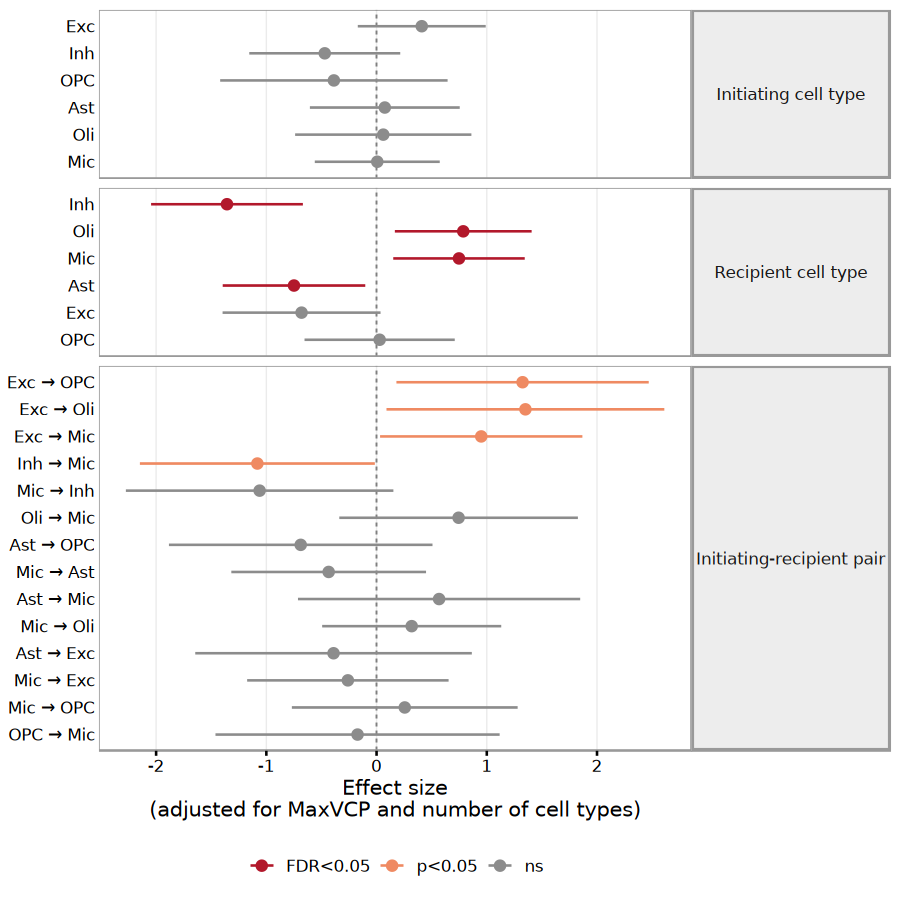

In [2]:
sig_colors <- c("FDR<0.05" = "#B2182B", "p<0.05" = "#EF8A62", "ns" = "grey55")
a$label <- gsub(" -> ", " \u2192 ", a$label)
a$y <- paste(a$model, a$label, sep = "::")
a$y <- factor(a$y, levels = rev(a$y))
a$sig <- factor(a$sig, levels = names(sig_colors))
p <- ggplot(a, aes(x = estimate, y = y, color = sig)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50", linewidth = 0.4) +
  geom_errorbar(aes(xmin = ci_low, xmax = ci_high), width = 0, orientation = "y", linewidth = 0.55) +
  geom_point(size = 2.4) +
  facet_grid(rows = vars(model), scales = "free_y", space = "free_y") +
  scale_y_discrete(labels = function(x) sub("^.*::", "", x)) +
  scale_color_manual(values = sig_colors, name = NULL, drop = FALSE) +
  labs(x = "Effect size\n(adjusted for MaxVCP and number of cell types)", y = NULL) +
  theme_classic(base_size = 12) +
  theme(strip.background = element_rect(fill = "grey93", color = "grey60"),
        strip.text.y = element_text(angle = 0), panel.border = element_rect(color = "grey60", fill = NA),
        axis.line = element_blank(), axis.ticks.y = element_blank(), legend.position = "bottom",
        panel.grid.major.x = element_line(color = "grey92", linewidth = 0.3))
options(repr.plot.width = 7.5, repr.plot.height = 7.5)
p